SETUP:

In [1]:
# SET HYPERPARAMETERS

In [2]:
# IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix, accuracy_score, log_loss, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
# LOAD DATA

data = pd.read_csv("recipe_site_traffic_2212.csv")

DATA VALIDATION:

In [4]:
# INSPECT DATA

"""
print(data.head())
print(data.dtypes)
print(data.describe())
print(data.isna().sum())
print(f"Unique values {data['recipe'].nunique()} out of {len(data['recipe'])} observations")
print(f"{data.loc[data[['calories', 'carbohydrate', 'sugar', 'protein']].isna().all(axis=1),'recipe'].count()} rows with all nutrition info as NaN from 52 rows with at least one NaN")
print(data["category"].value_counts())
print(data["high_traffic"].value_counts())
print(data["servings"].value_counts())
data.groupby(["category", "servings"]).size()
"""



'\nprint(data.head())\nprint(data.dtypes)\nprint(data.describe())\nprint(data.isna().sum())\nprint(f"Unique values {data[\'recipe\'].nunique()} out of {len(data[\'recipe\'])} observations")\nprint(f"{data.loc[data[[\'calories\', \'carbohydrate\', \'sugar\', \'protein\']].isna().all(axis=1),\'recipe\'].count()} rows with all nutrition info as NaN from 52 rows with at least one NaN")\nprint(data["category"].value_counts())\nprint(data["high_traffic"].value_counts())\nprint(data["servings"].value_counts())\ndata.groupby(["category", "servings"]).size()\n'

In [5]:
# ADJUST DATA

# Merge categories
data["category"] = data["category"].replace("Chicken Breast", "Chicken")
# Extract numeric information from servings and transform into numeric
data["servings"] = pd.to_numeric(data["servings"].str.replace(r"\D", "", regex=True), errors="coerce")
# Fill in low category instead of NaN
data["high_traffic"] = data["high_traffic"].fillna("Low")
# Create numerical target variable
data["traffic"] = data["high_traffic"].map({"Low": 0, "High": 1})
# To nutrition columns input means of observations with same category and servings
nutrition_cols = ["calories", "carbohydrate", "sugar", "protein"]
for col in nutrition_cols:
    data[col] = data[col].fillna(
        data.groupby(["category", "servings"])[col].transform("mean")
    )


In [6]:
# INSPECT DATA

"""
print(data.head())
print(data.dtypes)
print(data.describe())
print(data.isna().sum())
print(data["category"].value_counts())
print(data["high_traffic"].value_counts())
print(data["servings"].value_counts())
data.groupby(["category", "servings"]).size()
"""



'\nprint(data.head())\nprint(data.dtypes)\nprint(data.describe())\nprint(data.isna().sum())\nprint(data["category"].value_counts())\nprint(data["high_traffic"].value_counts())\nprint(data["servings"].value_counts())\ndata.groupby(["category", "servings"]).size()\n'

EXPLORATORY DATA ANALYSIS:

In [7]:
### 2 PLOTS OF 1 VARIABLE

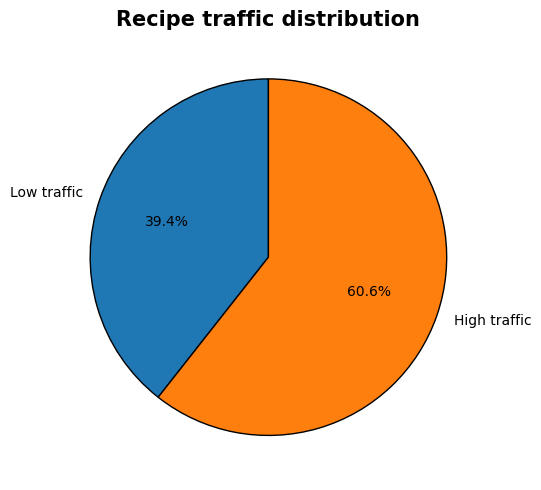

In [8]:
# PLOT 1: HIGH-TRAFFIC RECIPE DISTRIBUTION

counts = (
    data["high_traffic"]
    .value_counts()
    .reindex(["Low", "High"], fill_value=0)
)

labels = ["Low traffic", "High traffic"]

plt.figure(figsize=(7, 5))

plt.pie(
    counts.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

plt.title(
    "Recipe traffic distribution",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("plot11.png", bbox_inches="tight", dpi=300)
plt.show()

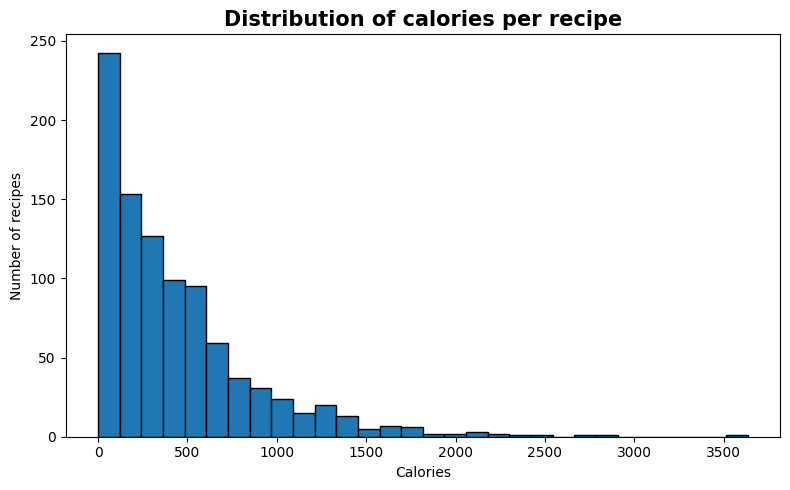

In [9]:
# PLOT 2: DISTRIBUTION OF CALORIES

calories = data["calories"].dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    calories,
    bins=30,
    edgecolor="black"
)

plt.title(
    "Distribution of calories per recipe",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Calories")
plt.ylabel("Number of recipes")

plt.tight_layout()
plt.savefig("plot12.png", bbox_inches="tight", dpi=300)
plt.show()

In [10]:
### 2 PLOTS OF 2 VARIABLES

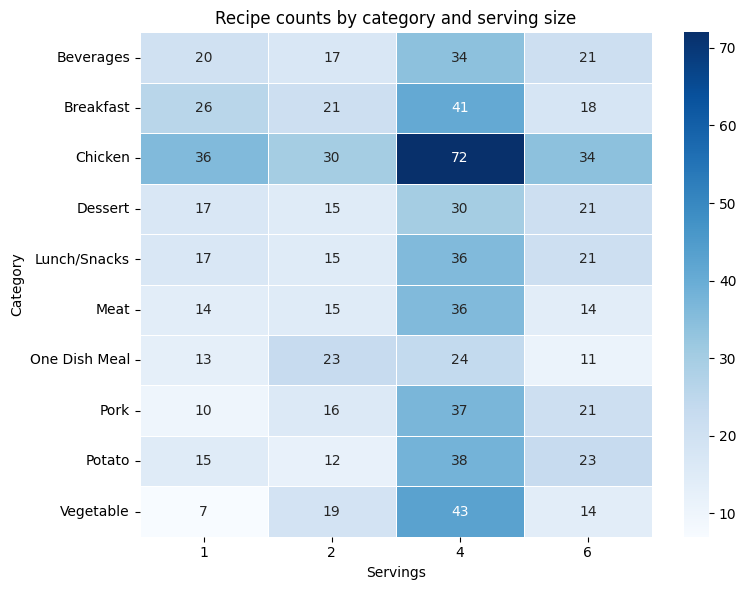

In [11]:
# PLOT 2: HEATMAP + CONTINGENCY TABLE OF CATEGORY x SERVINGS



plt.figure(figsize=(8, 6))
counts = pd.crosstab(data["category"], data["servings"])
sns.heatmap(
    counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.xlabel("Servings")
plt.ylabel("Category")
plt.title("Recipe counts by category and serving size")
plt.tight_layout()
plt.savefig("plot21.png", bbox_inches="tight", dpi=300)
plt.show()

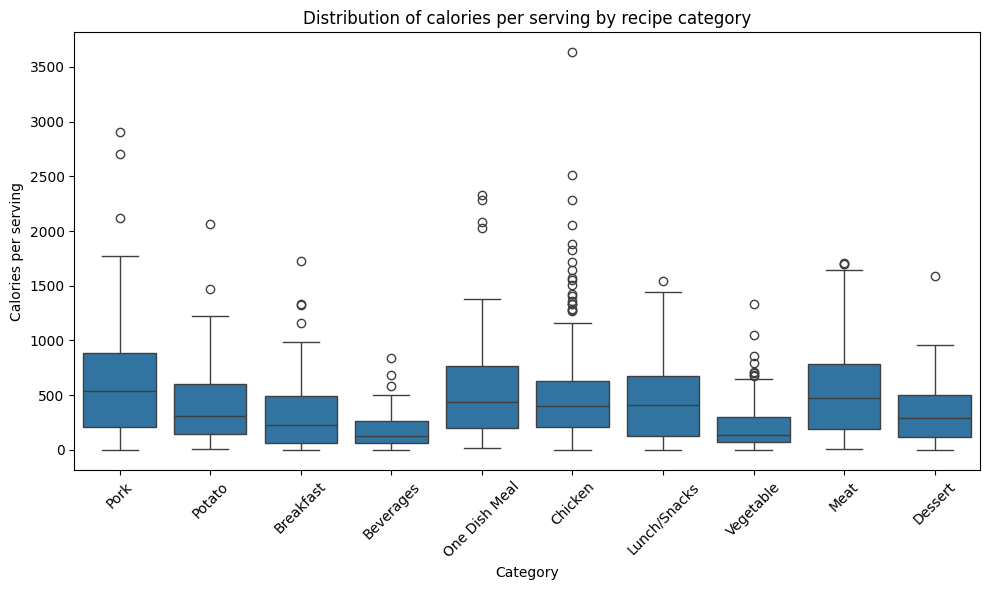

In [12]:
# PLOT 2: BOXPLOT OF CALORIES GROUPED BY CATEGORY

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="category",
    y="calories"
)

plt.xlabel("Category")
plt.ylabel("Calories per serving")
plt.title("Distribution of calories per serving by recipe category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("plot22.png", bbox_inches="tight", dpi=300)
plt.show()

MODEL DEVELOPMENT:

In [13]:
# PREPARE DATA FOR BUILDING MODELS

# DECLARE TARGET AND PREDICTORS
X = data.drop(columns=['traffic', 'high_traffic', 'recipe'])
X = pd.get_dummies(X, drop_first=True)
y = data['traffic']


# TRAIN / VALIDATION / TEST SPLIT
# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
# Second split: divide the remaining 20% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# STANDARDIZE FOR LOGISTIC REGRESSION
scaler = StandardScaler()
# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)
# Apply the same scaler to validation and test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [14]:
# MODEL 1: LOGISTIC REGRESSION


# DEFINE AND FIT MODEL ON TRAINING DATA
lr_model = LogisticRegression(
    solver='saga',
    C=1.0,
    l1_ratio=0.0,       # Pure L2 regularization
    max_iter=10000,
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)


# GENERATE PROBABILITIES
# Training probabilities
train_probs = lr_model.predict_proba(X_train_scaled)[:, 1]
# Validation probabilities
val_probs = lr_model.predict_proba(X_val_scaled)[:, 1]
# Test probabilities
test_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

# OPTIMIZE THRESHOLD ON VALIDATION DATA ONLY
thresholds = np.linspace(0.001, 0.999, 1000)
best_threshold = None
best_precision = -1.0
best_recall = -1.0
for t in thresholds:
    val_preds = (val_probs >= t).astype(int)
    current_recall = recall_score(
        y_val, val_preds, zero_division=0
    )
    current_precision = precision_score(
        y_val, val_preds, zero_division=0
    )
    # Business constraint:
    # Recall must be at least 80%
    if current_recall >= 0.80:
        # Within that constraint, maximize precision
        if current_precision > best_precision:
            best_precision = current_precision
            best_recall = current_recall
            best_threshold = t


# APPLY THE OPTIMAL THRESHOLD
train_preds = (train_probs >= best_threshold).astype(int)
val_preds   = (val_probs >= best_threshold).astype(int)
test_preds  = (test_probs >= best_threshold).astype(int)


# CALCULATE PERFORMANCE
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }
train_results = evaluate_model(y_train, train_preds)
val_results   = evaluate_model(y_val, val_preds)
test_results  = evaluate_model(y_test, test_preds)


# SHOW RESULTS
print("=" * 60)
print("       LOGISTIC REGRESSION RESULTS")
print("=" * 60)
print(f"\nOptimized threshold: {best_threshold:.3f}")
print("\nTRAINING SET")
print(f"Accuracy : {train_results['Accuracy']:.3f}")
print(f"Precision: {train_results['Precision']:.3f}")
print(f"Recall   : {train_results['Recall']:.3f}")
print(f"F1 Score : {train_results['F1']:.3f}")
print("\nVALIDATION SET")
print(f"Accuracy : {val_results['Accuracy']:.3f}")
print(f"Precision: {val_results['Precision']:.3f}")
print(f"Recall   : {val_results['Recall']:.3f}")
print(f"F1 Score : {val_results['F1']:.3f}")
print("\nTEST SET — FINAL EVALUATION")
print(f"Accuracy : {test_results['Accuracy']:.3f}")
print(f"Precision: {test_results['Precision']:.3f}")
print(f"Recall   : {test_results['Recall']:.3f}")
print(f"F1 Score : {test_results['F1']:.3f}")
print("=" * 60)

       LOGISTIC REGRESSION RESULTS

Optimized threshold: 0.402

TRAINING SET
Accuracy : 0.744
Precision: 0.741
Recall   : 0.887
F1 Score : 0.808

VALIDATION SET
Accuracy : 0.821
Precision: 0.860
Recall   : 0.845
F1 Score : 0.852

TEST SET — FINAL EVALUATION
Accuracy : 0.747
Precision: 0.746
Recall   : 0.877
F1 Score : 0.806


In [15]:
# INSPECT MODEL FIT

# DATA DISTRIBUTION OF EACH SUBSET
print("Train:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

print("\nClass distribution:")
print(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
}))

# CONFUSION MATRIX
print("TRAIN")
print(confusion_matrix(y_train, train_preds))
print("\nVALIDATION")
print(confusion_matrix(y_val, val_preds))
print("\nTEST")
print(confusion_matrix(y_test, test_preds))

Train: 757
Validation: 95
Test: 95

Class distribution:
            Train  Validation  Test
traffic                            
1        0.606341    0.610526   0.6
0        0.393659    0.389474   0.4
TRAIN
[[156 142]
 [ 52 407]]

VALIDATION
[[29  8]
 [ 9 49]]

TEST
[[21 17]
 [ 7 50]]


In [16]:
# MODEL 2: XGBOOST

xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    
    max_depth=2,
    n_estimators=100,
    learning_rate=0.1,
    
    min_child_weight=5,
    reg_lambda=1.0,
    
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

# 1. FIT MODEL ON TRAINING DATA
xgb_model.fit(X_train, y_train)


# 2. GENERATE PROBABILITIES
train_probs = xgb_model.predict_proba(X_train)[:, 1]
val_probs = xgb_model.predict_proba(X_val)[:, 1]
test_probs = xgb_model.predict_proba(X_test)[:, 1]


# 3. OPTIMIZE THRESHOLD ON VALIDATION DATA
thresholds = np.linspace(0.001, 0.999, 1000)

best_xgb_threshold = None
best_xgb_precision = -1.0
best_xgb_recall = -1.0

for t in thresholds:
    val_preds = (val_probs >= t).astype(int)

    current_recall = recall_score(
        y_val,
        val_preds,
        zero_division=0
    )

    current_precision = precision_score(
        y_val,
        val_preds,
        zero_division=0
    )

    # Constraint: recall must be at least 80%
    if current_recall >= 0.80:

        # Among eligible thresholds, maximize precision
        if current_precision > best_xgb_precision:
            best_xgb_precision = current_precision
            best_xgb_recall = current_recall
            best_xgb_threshold = t


# 4. APPLY THE FIXED THRESHOLD TO ALL DATASETS
train_preds = (train_probs >= best_xgb_threshold).astype(int)
val_preds = (val_probs >= best_xgb_threshold).astype(int)
test_preds = (test_probs >= best_xgb_threshold).astype(int)


# 5. EVALUATION FUNCTION
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }


# 6. CALCULATE RESULTS
train_results = evaluate_model(y_train, train_preds)
val_results = evaluate_model(y_val, val_preds)
test_results = evaluate_model(y_test, test_preds)


# 7. DISPLAY RESULTS
print("=" * 55)
print("              XGBOOST RESULTS")
print("=" * 55)

print(f"\nSelected threshold: {best_xgb_threshold:.3f}")

print("\nTRAIN")
print("-" * 30)
for metric, value in train_results.items():
    print(f"{metric}: {value:.3f}")

print("\nVALIDATION")
print("-" * 30)
for metric, value in val_results.items():
    print(f"{metric}: {value:.3f}")

print("\nTEST")
print("-" * 30)
for metric, value in test_results.items():
    print(f"{metric}: {value:.3f}")

              XGBOOST RESULTS

Selected threshold: 0.412

TRAIN
------------------------------
Accuracy: 0.769
Precision: 0.756
Recall: 0.913
F1: 0.827

VALIDATION
------------------------------
Accuracy: 0.779
Precision: 0.803
Recall: 0.845
F1: 0.824

TEST
------------------------------
Accuracy: 0.705
Precision: 0.730
Recall: 0.807
F1: 0.767


In [17]:
# INSPECT MODEL FIT

# DATA DISTRIBUTION OF EACH SUBSET
print("Train:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

print("\nClass distribution:")
print(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
}))

# CONFUSION MATRIX
print("TRAIN")
print(confusion_matrix(y_train, train_preds))
print("\nVALIDATION")
print(confusion_matrix(y_val, val_preds))
print("\nTEST")
print(confusion_matrix(y_test, test_preds))

Train: 757
Validation: 95
Test: 95

Class distribution:
            Train  Validation  Test
traffic                            
1        0.606341    0.610526   0.6
0        0.393659    0.389474   0.4
TRAIN
[[163 135]
 [ 40 419]]

VALIDATION
[[25 12]
 [ 9 49]]

TEST
[[21 17]
 [11 46]]
